# 02 · Harmonisation onto one grid (Phase 2)
Every dataset → 0.25° cell centres, UTC daily, canonical units, ocean mask. One **conservative (area-weighted)** operator
(`src/oceanembed_ml/grid.py`) that reduces to the identity / exact block mean when grids nest.

In [1]:
import json, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from oceanembed_ml.config import ROOT, AUDIT, INTERIM, PROCESSED, FINAL, FIGURES, load_yaml
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
print("project root:", ROOT)

project root: D:\Ml project


## The operator on a toy example: a 2×2 nested grid gives exactly the block mean

In [2]:
from oceanembed_ml.grid import ConservativeRegridder, LAT, LON
lat = np.round(np.arange(4.5625, 30.5, 0.125), 4); lon = np.round(np.arange(44.5625, 105.5, 0.125), 4)
x = np.random.default_rng(0).normal(size=(lat.size, lon.size))
out = ConservativeRegridder(lat, lon)(x)
print("native", x.shape, "-> canonical", out.shape)
print("constant field preserved:", np.allclose(ConservativeRegridder(lat, lon)(np.full_like(x, 7.5)), 7.5))

native (208, 488) -> canonical (101, 241)
constant field preserved: True


## QC summary after harmonisation (`data/audit/harmonisation_qc.json`)

In [3]:
qc = json.loads((AUDIT/"harmonisation_qc.json").read_text())
rows = [{"source": s, "var": v, **{k: r.get(k) for k in ["valid_frac_over_ocean","n_ocean_cells_never_valid","n_out_of_range_set_nan","min","max"]}}
        for s, d in qc.items() if s != "glorys" for v, r in d.items() if isinstance(r, dict) and "min" in r]
print("ocean cells:", qc["glorys"]["masks"]["n_ocean_cells"])
pd.DataFrame(rows)

ocean cells: 11880


,source,var,valid_frac_over_ocean,n_ocean_cells_never_valid,n_out_of_range_set_nan,min,max
0,glorys_clim,thetao,NaN,NaN,0,6.223177,34.808659
1,ssh,sla,1.00000,0.0,0,-0.421874,0.618380
2,ssh,uo,0.99933,8.0,0,-2.017556,2.623589
3,ssh,vo,0.99933,8.0,0,-1.902683,1.854826
4,sss,sss,0.99747,30.0,0,25.991749,40.030697
5,sst,sst,0.99832,20.0,0,15.858556,36.439697
6,winds,u10,1.00000,0.0,0,-17.682590,19.731850
7,winds,v10,1.00000,0.0,0,-15.171436,18.058855


## Native vs harmonised (2021-08-15)

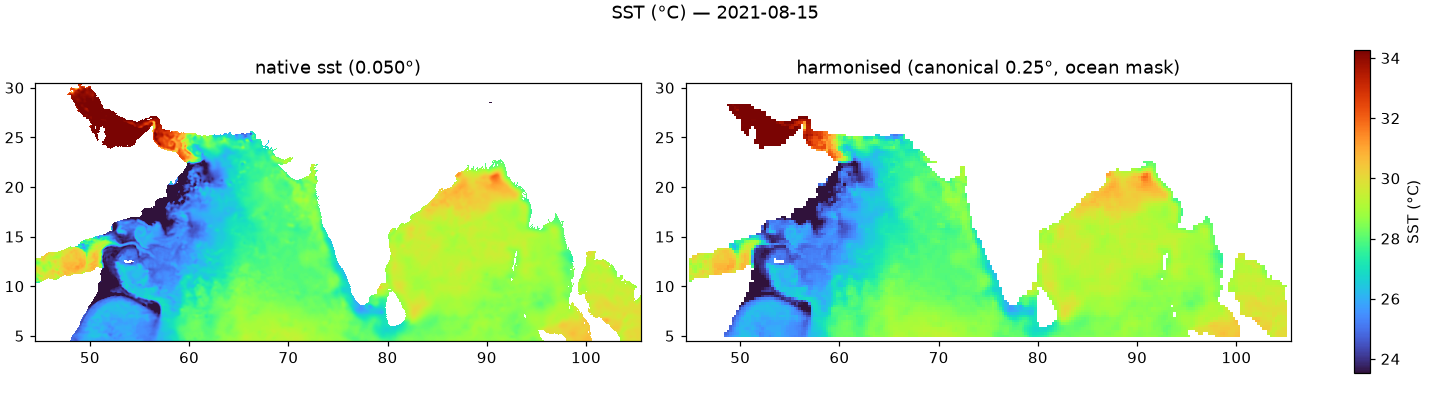

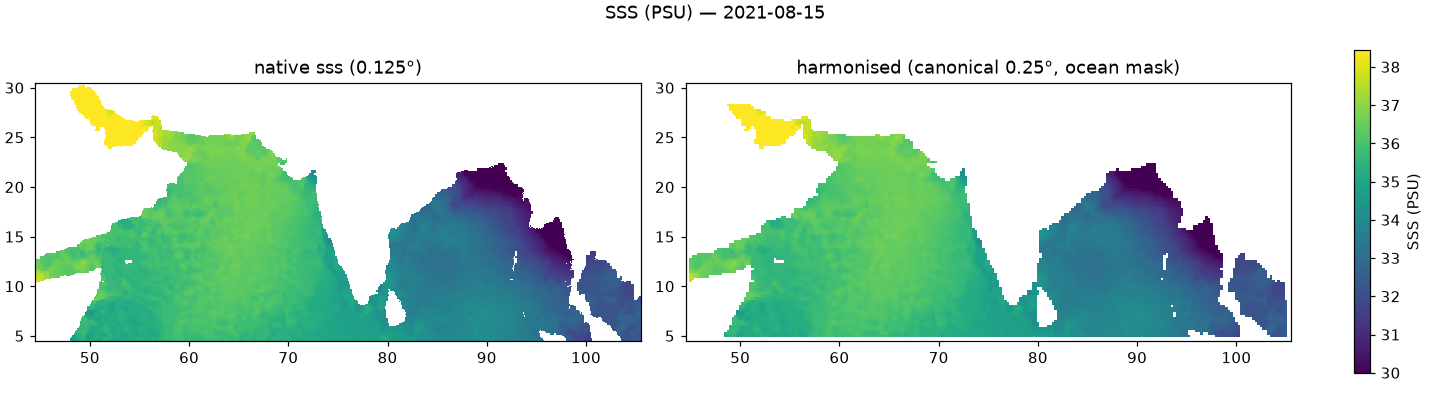

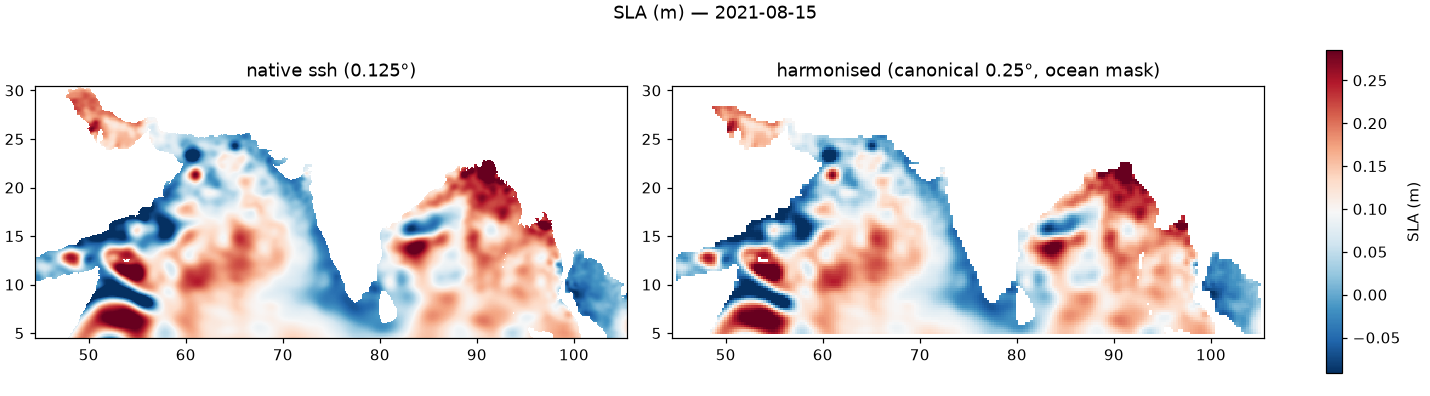

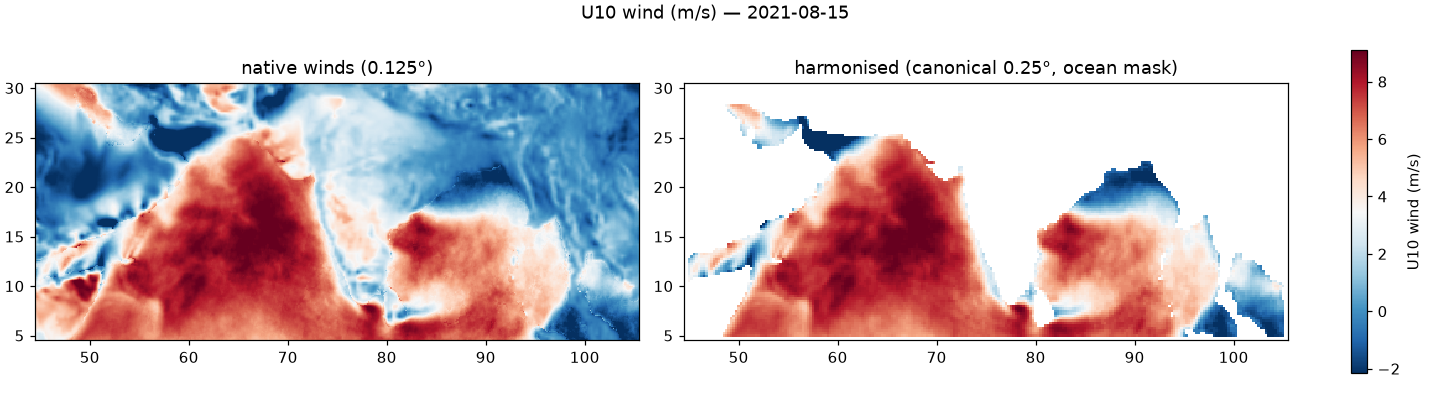

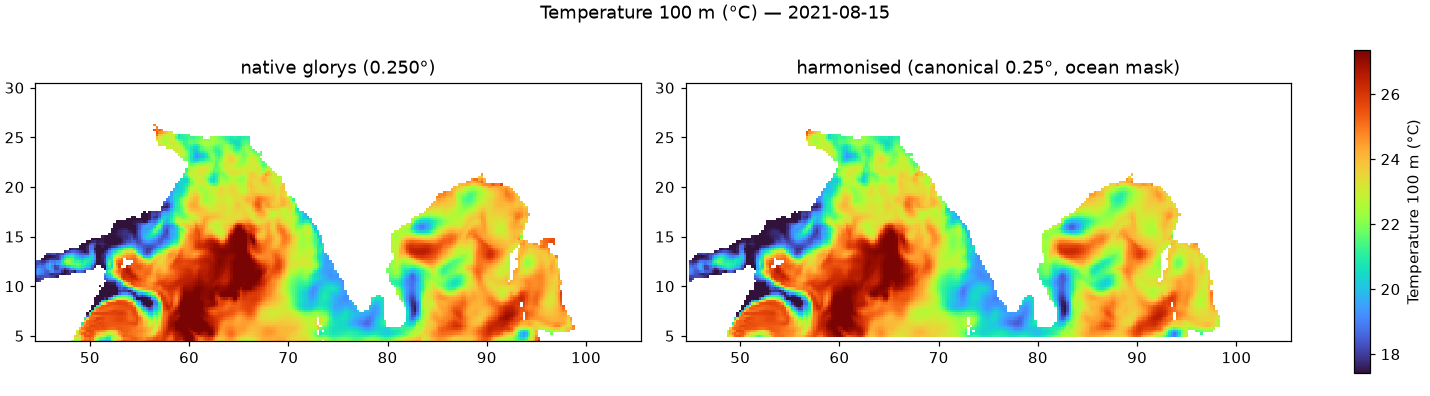

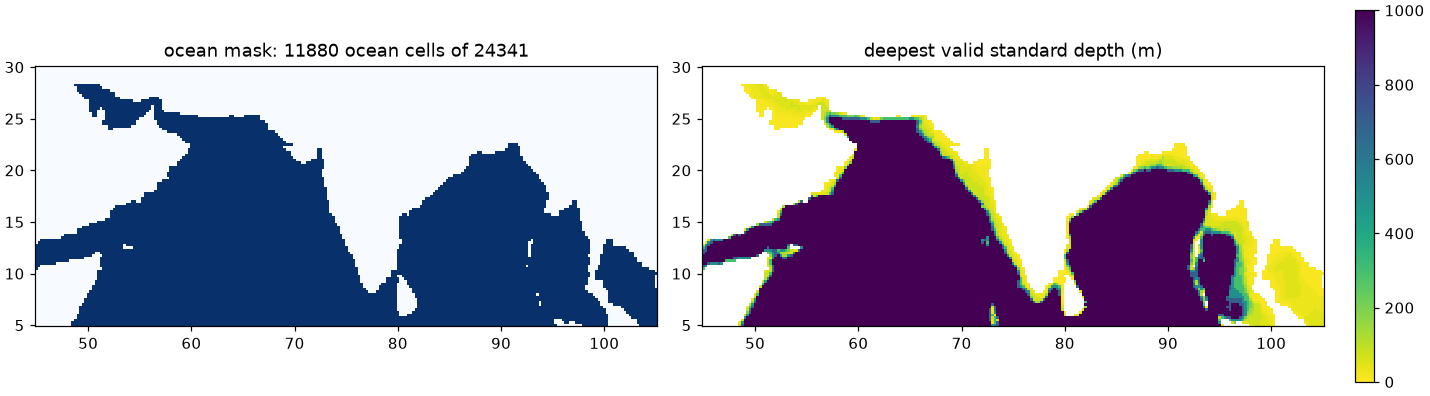

In [4]:
for f in ["compare_sst.png","compare_sss.png","compare_sla.png","compare_u10.png","compare_thetao.png","masks.png"]:
    display(Image(filename=str(FIGURES/"phase2"/f)))

**Note (decision D-016):** a 35 °C plausibility cap would have deleted real Persian Gulf summer SST (up to 36.7 °C); the cap is 38 °C.